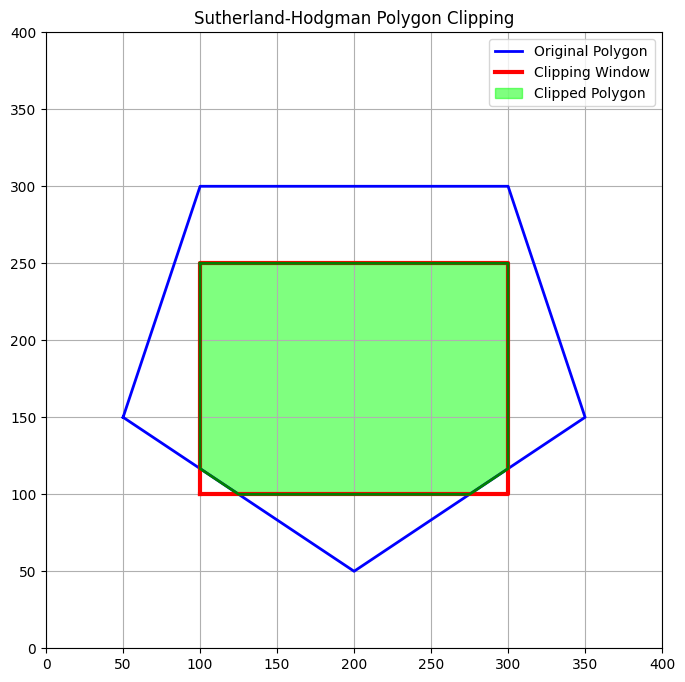

In [1]:
import matplotlib.pyplot as plt

# -----------------------------
# Sutherland-Hodgman Polygon Clipping
# -----------------------------

def inside(p, edge):
    x, y = p
    x1, y1 = edge[0]
    x2, y2 = edge[1]
    return (x2 - x1) * (y - y1) - (y2 - y1) * (x - x1) >= 0


def intersection(p1, p2, edge):
    x1, y1 = p1
    x2, y2 = p2
    x3, y3 = edge[0]
    x4, y4 = edge[1]

    den = (x1-x2)*(y3-y4) - (y1-y2)*(x3-x4)

    if den == 0:
        return p2

    px = ((x1*y2-y1*x2)*(x3-x4) - (x1-x2)*(x3*y4-y3*x4))/den
    py = ((x1*y2-y1*x2)*(y3-y4) - (y1-y2)*(x3*y4-y3*x4))/den

    return (px, py)


def clip(subjectPolygon, clipPolygon):

    output = subjectPolygon

    for i in range(len(clipPolygon)):
        inputList = output
        output = []

        A = clipPolygon[i]
        B = clipPolygon[(i + 1) % len(clipPolygon)]
        edge = (A, B)

        if not inputList:
            break

        S = inputList[-1]

        for E in inputList:

            if inside(E, edge):
                if not inside(S, edge):
                    output.append(intersection(S, E, edge))
                output.append(E)

            elif inside(S, edge):
                output.append(intersection(S, E, edge))

            S = E

    return output


# -----------------------------
# Input Polygon
# -----------------------------
subject = [
    (50, 150),
    (200, 50),
    (350, 150),
    (300, 300),
    (100, 300)
]

# Rectangular Clipping Window
clipper = [
    (100,100),
    (300,100),
    (300,250),
    (100,250)
]

# Perform clipping
result = clip(subject, clipper)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8,8))

# Original Polygon
sx = [p[0] for p in subject] + [subject[0][0]]
sy = [p[1] for p in subject] + [subject[0][1]]
plt.plot(sx, sy, 'b-', linewidth=2, label="Original Polygon")

# Clipping Window
cx = [p[0] for p in clipper] + [clipper[0][0]]
cy = [p[1] for p in clipper] + [clipper[0][1]]
plt.plot(cx, cy, 'r-', linewidth=3, label="Clipping Window")

# Clipped Polygon
if result:
    rx = [p[0] for p in result] + [result[0][0]]
    ry = [p[1] for p in result] + [result[0][1]]
    plt.fill(rx, ry, color='lime', alpha=0.5, label="Clipped Polygon")
    plt.plot(rx, ry, 'g-', linewidth=2)

plt.title("Sutherland-Hodgman Polygon Clipping")
plt.xlim(0,400)
plt.ylim(0,400)
plt.gca().set_aspect('equal')
plt.grid(True)
plt.legend()

plt.show()